# 空間アルゴリズム-spatial

## この章で学ぶこと

`scipy.spatial` には、空間のデータを扱うクラスと関数があります。近い点を探す、点の集まりを囲む、空間を分ける、といった計算ができます。

- 最近傍点を探す(`KDTree`、`distance`)
- 凸包(`ConvexHull`)
- ボロノイ図(`Voronoi`)
- ドロネー三角形分割(`Delaunay`)

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import helper.matplotlib
import helper.magics
from scipy import spatial  # 空間アルゴリズムのモジュール

## 最近傍点の計算

1 次元で昇順に並べた数値なら、2 分探索で、指定した値に最も近い値を速く探せます。次の例では、昇順に並べた乱数 `x` で、`searchsorted()` を使って 0.5 に最も近い値を探します。並べ替えに $O(N \log N)$、1 回の探索に $O(\log N)$ かかります。

In [2]:
x = np.sort(np.random.rand(100))
idx = np.searchsorted(x, 0.5)  # 0.5 を入れる位置
print(x[idx], x[idx - 1])  # 0.5に最も近い数値はこの2つのうちの1つです

0.5006968640429348 0.4990005943528466


同じ考え方は N 次元でも使えます。`KDTree` は k-d 木を作り、N 次元空間の最近傍点を速く探します。

次の例では、平面の 100 点で `KDTree` を作り、`targets` の各点に近い 3 点を探します。`query()` は距離 `dist` と番号 `idx` を返します。`dist[i, :]` が `targets[i]` から近い順の距離、`idx[i, :]` がその点の番号です。

In [3]:
from scipy import spatial

np.random.seed(42)
N = 100
points = np.random.uniform(-1, 1, (N, 2))  # 平面の N 点
kd = spatial.KDTree(points)  # k-d 木を作る

targets = np.array([(0, 0), (0.5, 0.5), (-0.5, 0.5), (0.5, -0.5), (-0.5, -0.5)])
dist, idx = kd.query(targets, 3)  # 各点に近い 3 点
%C dist; idx

                 dist                        idx      
--------------------------------------  --------------
[[0.15188266, 0.21919416, 0.27647793],  [[48, 73, 81],
 [0.09595807, 0.15745334, 0.22855398],   [37, 78, 43],
 [0.05009422, 0.17583445, 0.1807312 ],   [79, 22, 92],
 [0.11180181, 0.16618122, 0.18127473],   [35, 58,  6],
 [0.19015485, 0.19060739, 0.19361173]]   [83,  7, 42]]


`query_ball_point()` は、指定した点から一定の距離以内にある点をすべて探します。返るのは番号だけです。点ごとに近傍の数が違うので、`idx2` の各要素はリストになります。

In [4]:
r = 0.2
idx2 = kd.query_ball_point(targets, r)  # 半径 r 以内の点
idx2

array([list([48]), list([37, 78]), list([22, 79, 92]), list([6, 35, 58]),
       list([7, 42, 55, 83])], dtype=object)

`query_pairs()` は、`points` の中で距離が指定より小さい組をすべて探します。返るのは番号の組の集合です。次のコードは、集合の差を取って、距離が 0.08 から 0.1 の間にある組を求めます。

In [5]:
idx3 = kd.query_pairs(0.1) - kd.query_pairs(0.08)  # 距離が 0.08〜0.1 の組
%col 6 idx3

{(1, 46),     (3, 21),     (3, 82),     (3, 95),     (5, 16),     (9, 30),    
 (10, 87),    (11, 42),    (11, 97),    (18, 41),    (29, 74),    (32, 51),   
 (37, 78),    (39, 61),    (41, 61),    (50, 84),    (55, 83),    (73, 81)}   


次の図では、`targets` の各点(星印)に近い点を、同じ色の丸で囲んでいます。左が `query()` の 3 近傍、中が `query_ball_point()` の半径 `r` 以内、右が距離が 0.08 から 0.1 の組です。

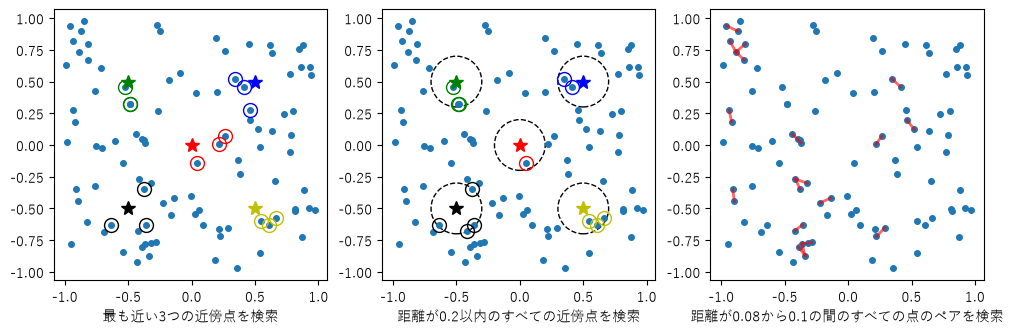

In [6]:
x, y = points.T  # 点の座標
colors = "r", "b", "g", "y", "k"

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))

for ax in ax1, ax2, ax3:
    ax.set_aspect("equal")
    ax.plot(x, y, "o", markersize=4)

for ax in ax1, ax2:
    for i in range(len(targets)):
        c = colors[i]
        tx, ty = targets[i]
        ax.plot([tx], [ty], "*", markersize=10, color=c)

for i in range(len(targets)):
    nx, ny = points[idx[i]].T
    ax1.plot(
        nx,
        ny,
        "o",
        markersize=10,
        markerfacecolor="None",
        markeredgecolor=colors[i],
        markeredgewidth=1,
    )

    nx, ny = points[idx2[i]].T
    ax2.plot(
        nx,
        ny,
        "o",
        markersize=10,
        markerfacecolor="None",
        markeredgecolor=colors[i],
        markeredgewidth=1,
    )

    ax2.add_artist(plt.Circle(targets[i], r, fill=None, linestyle="dashed"))

for pidx1, pidx2 in idx3:
    sx, sy = points[pidx1]
    ex, ey = points[pidx2]
    ax3.plot([sx, ex], [sy, ey], "r", linewidth=2, alpha=0.6)

ax1.set_xlabel("最も近い3つの近傍点を検索")
ax2.set_xlabel("距離が0.2以内のすべての近傍点を検索")
ax3.set_xlabel("距離が0.08から0.1の間のすべての点のペアを検索");

`KDTree` の探索メソッドには、距離の計算方法を決める `p` があります。`p` を変えて、上の図がどう変わるか見てください。

* `p = 1`：座標の差の絶対値の合計(マンハッタン距離)
* `p = 2`：ユークリッド距離
* `p = np.inf`：座標の差の最大値(チェビシェフ距離)

`query_ball_tree()` は、2 つの k-d 木の間で、距離が指定より小さい組を探します。

`distance` モジュールの `pdist()` は、1 つの点の集まりの中で、すべての 2 点の距離を計算します。`cdist()` は、2 つの集まりの間の距離を計算します。`pdist()` が返すのは 1 次元に詰めた配列なので、`squareform()` で 2 次元に戻します。`dist1[i, j]` が `points` の i と j の距離、`dist2[i, j]` が `points[i]` と `targets[j]` の距離です。

In [7]:
from scipy.spatial import distance

dist1 = distance.squareform(distance.pdist(points))  # 全 2 点の距離
dist2 = distance.cdist(points, targets)  # points と targets の距離
%C dist1.shape; dist2.shape

dist1.shape  dist2.shape
-----------  -----------
(100, 100)   (100, 5)   


`np.min()` で `dist2` の各列の最小値を取ると、`targets` に最も近い点までの距離になります。`KDTree.query()` の結果と同じです。

In [8]:
print(dist[:, 0])  # KDTree.query()が返すtargetsに最も近い距離
print(np.min(dist2, axis=0))

[0.15188266 0.09595807 0.05009422 0.11180181 0.19015485]
[0.15188266 0.09595807 0.05009422 0.11180181 0.19015485]


`points` の中で最も近い 2 点を探すには、`dist1` の対角要素を無限大にしてから最小値を探します。対角要素は自分自身との距離で 0 になるからです。

In [9]:
dist1[np.diag_indices(len(points))] = np.inf  # 自分自身との距離を除く
nearest_pair = np.unravel_index(np.argmin(dist1), dist1.shape)
print(nearest_pair, dist1[nearest_pair])

(np.int64(22), np.int64(92)) 0.005346210248158245


`KDTree.query()` でも同じ組を探せます。k-d 木自身の点を問い合わせて、各点に近い 2 点を求めます。1 番目は自分自身で距離 0、2 番目が最近傍点です。2 番目の距離が最小の点を選べば、最も近い組が分かります。

In [10]:
dist, idx = kd.query(points, 2)  # 自分と最近傍の 2 点
print(idx[np.argmin(dist[:, 1])], np.min(dist[:, 1]))

[22 92] 0.005346210248158245


## 凸包

凸包は、点の集まりをぴったり囲む最小の凸図形です。2 次元なら凸多角形、3 次元なら凸多面体になります。`ConvexHull` は、N 次元の点の集まりの凸包を計算します。

2 次元の例です。`points2d` が平面上の点、`ch2d` がその凸包です。`simplices` は凸包の各辺の両端の番号で、形が `(5, 2)` なので、凸包は 5 本の線分でできています。2 次元では、`vertices` が凸多角形の頂点の番号で、反時計回りの順に並びます。

In [11]:
np.random.seed(42)
points2d = np.random.rand(10, 2)
ch2d = spatial.ConvexHull(points2d)  # 2 次元の凸包
%C ch2d.simplices; ch2d.vertices

ch2d.simplices   ch2d.vertices 
--------------  ---------------
[[2, 5],        [5, 2, 6, 1, 0]
 [2, 6],                       
 [0, 5],                       
 [1, 6],                       
 [1, 0]]                       


`matplotlib` の `Polygon` で、次の図の多角形を描けます。

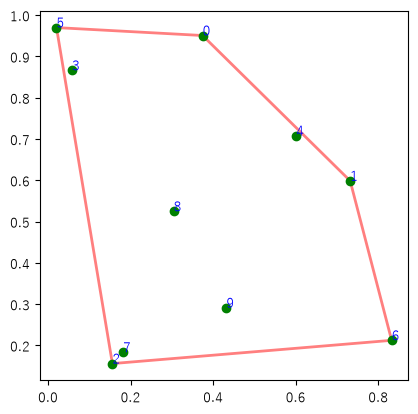

In [12]:
poly = plt.Polygon(points2d[ch2d.vertices], fill=None, lw=2, color="r", alpha=0.5)  # 凸包の多角形
ax = plt.subplot(aspect="equal")
plt.plot(points2d[:, 0], points2d[:, 1], "go")
for i, pos in enumerate(points2d):
    plt.text(pos[0], pos[1], str(i), color="blue")
ax.add_artist(poly);

3 次元の凸包は凸多面体で、面は三角形です。`simplices` の形から、この凸包が 38 個の三角形でできていることが分かります。

In [13]:
np.random.seed(42)
points3d = np.random.rand(40, 3)
ch3d = spatial.ConvexHull(points3d)  # 3 次元の凸包
ch3d.simplices.shape

(38, 3)

次のプログラムは、PyVista で凸包を描きます。緑の球が `points3d` の点、赤い線で囲まれた三角形が凸多面体の面です。赤い線が通っていない点は、凸包の内側にあります。

In [14]:
import pyvista as pv
from helper.pyvista import plotter_to_iframe

hull = pv.PolyData.from_regular_faces(ch3d.points, faces=ch3d.simplices)  # 凸包の面を作る
points = pv.PolyData(points3d)
sphere = pv.Sphere(radius=0.02, theta_resolution=6, phi_resolution=6)
glyphs = points.glyph(orient=False, scale=False, geom=sphere)
plot = pv.Plotter()  # 描画の準備
plot.add_mesh(glyphs, color="green")
plot.add_mesh(hull, opacity=0.75, line_width=2, edge_color="red", show_edges=True)
plotter_to_iframe(plot)

C:\Users\ruoyu\Documents\notebooks\scipybook\scipybook\helper\pyvista.py:12: PyVistaDeprecationWarning: Plotter.export_vtksz is deprecated. Use plotter.trame.export_vtksz(...) instead. Install via `pip install trame-pyvista`.
  zip_data = plotter.export_vtksz(filename=None)


## ボロノイ図

ボロノイ図は、空間を母点の数だけの領域に分ける方法です。各領域の点は、その領域の母点に最も近くなります。

In [15]:
points2d = np.array(
    [
        [0.2, 0.1],
        [0.5, 0.5],
        [0.8, 0.1],
        [0.5, 0.8],
        [0.3, 0.6],
        [0.7, 0.6],
        [0.5, 0.35],
    ]
)
vo = spatial.Voronoi(points2d)  # ボロノイ図を計算

%C vo.vertices; vo.regions; vo.ridge_vertices

   vo.vertices          vo.regions     vo.ridge_vertices
------------------  -----------------  -----------------
[[0.5   , 0.045 ],  [[-1, 0, 1],       [[-1, 0],        
 [0.245 , 0.351 ],   [-1, 0, 2],        [0, 1],         
 [0.755 , 0.351 ],   [],                [-1, 1],        
 [0.3375, 0.425 ],   [6, 4, 3, 5],      [0, 2],         
 [0.6625, 0.425 ],   [5, -1, 1, 3],     [-1, 2],        
 [0.45  , 0.65  ],   [4, 2, 0, 1, 3],   [3, 5],         
 [0.55  , 0.65  ]]   [6, -1, 2, 4],     [3, 4],         
                     [6, -1, 5]]        [4, 6],         
                                        [5, 6],         
                                        [1, 3],         
                                        [-1, 5],        
                                        [2, 4],         
                                        [-1, 6]]        


`voronoi_plot_2d()` で、ボロノイ図を描けます。左の図の青い小さい点が母点、赤い大きい点が `vertices` で、番号を付けています。点線と実線で空間が 7 つの領域に分かれ、点線で囲まれた領域は無限に広がります。

`regions` は領域のリストで、各領域は `vertices` の番号のリストです。`-1` を含む領域は無限領域です。例えば `[6, 4, 3, 5]` は中央の領域です。

`ridge_vertices` は境界線のリストで、各境界線は `vertices` の 2 つの番号です。`-1` を含む境界線が、図の点線にあたります。

領域に色を塗りたいとき、外側の領域は無限なので、そのままでは描けません。外側に 4 点を足して全体を囲めば、各母点に有限の領域ができます。右の図では、黒い点が母点で、最も近い領域を母点の色で塗っています。

In [16]:
bound = np.array([[-100, -100], [-100, 100], [100, 100], [100, -100]])  # 外側を囲む 4 点
vo2 = spatial.Voronoi(np.vstack((points2d, bound)))  # 有限の領域にする

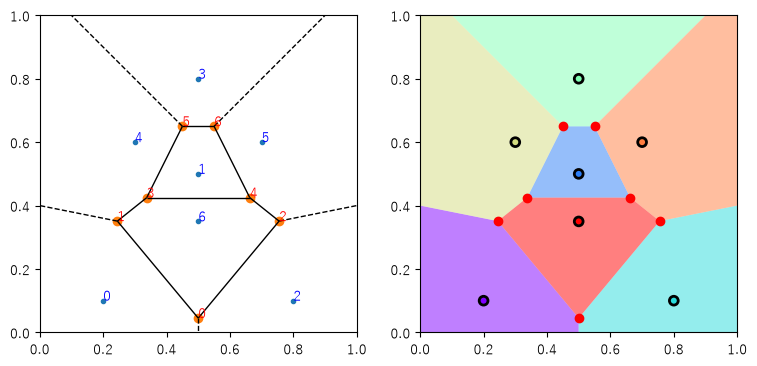

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.5))
ax1.set_aspect("equal")
ax2.set_aspect("equal")
spatial.voronoi_plot_2d(vo, ax=ax1)  # ボロノイ図を描く
for i, v in enumerate(vo.vertices):
    ax1.text(v[0], v[1], str(i), color="red")

for i, p in enumerate(points2d):
    ax1.text(p[0], p[1], str(i), color="blue")

n = len(points2d)
color = plt.cm.rainbow(np.linspace(0, 1, n))
for i in range(n):
    idx = vo2.point_region[i]
    region = vo2.regions[idx]
    poly = plt.Polygon(vo2.vertices[region], facecolor=color[i], alpha=0.5, zorder=0)
    ax2.add_artist(poly)
ax2.scatter(points2d[:, 0], points2d[:, 1], s=40, c=color, linewidths=2, edgecolors="k")
ax2.plot(vo2.vertices[:, 0], vo2.vertices[:, 1], "ro", ms=6)

for ax in ax1, ax2:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

ボロノイ図は、最大空円問題にも使えます。点の凸包の中で、中の点を含まない最大の円を探す問題です。この円の中心は `vertices` のどれかで、半径は最も近い母点までの距離です。

母点と `vertices` の関係は `point_region` で分かります。`point_region[i]` は、母点 `points2d[i]` に最も近い領域の番号です。次の出力では、番号 5 の青い点が領域 6 に対応し、`regions[6]` から、その領域が `vertices` の 6、2、4 でできていることが分かります(`-1` は無限遠を表します)。つまり、母点 `points2d[5]` に最も近い `vertices` は 2、4、6 のどれかです。

In [18]:
print(vo.point_region)
print(vo.regions[6])

[0 3 1 7 4 6 5]
[6, -1, 2, 4]


最大空円を計算するプログラムです。

❶ `Polygon.contains_point()` で、`ConvexHull` の凸包の多角形が `vertices` の点を含むかを調べ、❷ 凸包の外側の点を除きます。

❸ `vertice_point_map` は、`vertices` の番号をキー、その点に最も近い母点の番号を値とする辞書です。`point_region` と `regions` から作り、凸包の外側の点は入れません。

❹ 辞書の各点で、最も近い母点までの距離を計算し、最大のものを選ぶと、円の中心と半径が求まります。

r =  0.17427845676199402 , center =  [0.46973363 0.59356531]


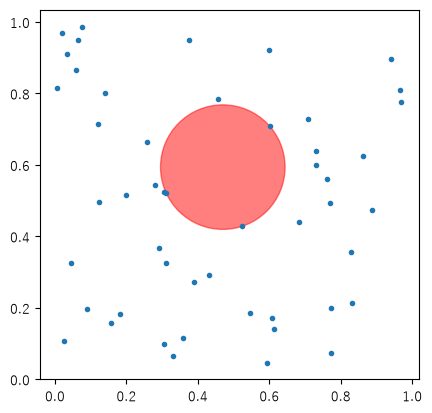

In [19]:
from collections import defaultdict

n = 50
np.random.seed(42)
points2d = np.random.rand(n, 2)
vo = spatial.Voronoi(points2d)
ch = spatial.ConvexHull(points2d)
poly = plt.Polygon(points2d[ch.vertices])  #❶
vs = vo.vertices
convexhull_mask = [poly.contains_point(p, radius=0) for p in vs]  #❷

vertice_point_map = defaultdict(list)  #❸
for index_point, index_region in enumerate(vo.point_region):
    region = vo.regions[index_region]
    if -1 in region:
        continue
    for index_vertice in region:
        if convexhull_mask[index_vertice]:
            vertice_point_map[index_vertice].append(index_point)


def dist(p1, p2):
    return ((p1 - p2) ** 2).sum() ** 0.5


max_cicle = max(
    (dist(points2d[pidxs[0]], vs[vidx]), vs[vidx])  #❹
    for vidx, pidxs in vertice_point_map.items()
)
r, center = max_cicle
print("r = ", r, ", center = ", center)

ax = plt.subplot(111, aspect="equal")
ax.plot(points2d[:, 0], points2d[:, 1], ".")

c = plt.Circle(center, r, fill=True, color="red", alpha=0.5)
ax.add_artist(c);

## ドロネー三角形分割

ドロネー三角形分割は、点の集まりの凸包を三角形に分ける方法です。各三角形の外接円には、他の点が入りません。

`Delaunay` オブジェクト `dy` の `simplices` は、各三角形の頂点の番号です。外接円の中心は、同じ点の集まりのボロノイ図の `vertices` から得られます。

In [20]:
x = np.array(
    [
        46.445,
        263.251,
        174.176,
        280.899,
        280.899,
        189.358,
        135.521,
        29.638,
        101.907,
        226.665,
    ]
)
y = np.array(
    [
        287.865,
        250.891,
        287.865,
        160.975,
        54.252,
        160.975,
        232.404,
        179.187,
        35.765,
        71.361,
    ]
)
points2d = np.c_[x, y]
dy = spatial.Delaunay(points2d)  # 三角形分割
vo = spatial.Voronoi(points2d)

%C dy.simplices; vo.vertices

dy.simplices           vo.vertices          
------------  ------------------------------
[[8, 5, 7],   [[104.58977484, 127.03566055],
 [1, 5, 3],    [235.1285    , 198.68143374],
 [5, 6, 7],    [107.83960707, 155.53682482],
 [6, 0, 7],    [ 71.22104881, 228.39479887],
 [0, 6, 2],    [110.3105    , 291.17642838],
 [6, 1, 2],    [201.40695449, 227.68436282],
 [1, 6, 5],    [201.61895891, 226.21958623],
 [9, 5, 8],    [152.96231864,  93.25060083],
 [4, 9, 8],    [205.40381294, -90.5480267 ],
 [5, 9, 3],    [235.1285    , 127.45701644],
 [9, 4, 3]]    [267.91709907, 107.6135    ]]


`delaunay_plot_2d()` で三角形分割を描き、外接円も描いてみます。どの三角形も、外接円の中に他の点が入っていないことが分かります。

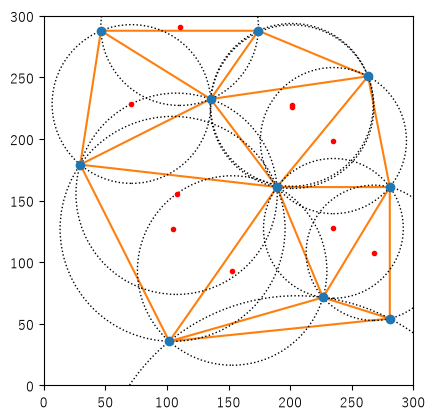

In [21]:
cx, cy = vo.vertices.T

ax = plt.subplot(aspect="equal")
spatial.delaunay_plot_2d(dy, ax=ax)  # 三角形を描く
ax.plot(cx, cy, "r.")
for i, (cx, cy) in enumerate(vo.vertices):
    px, py = points2d[dy.simplices[i, 0]]
    radius = np.hypot(cx - px, cy - py)
    circle = plt.Circle((cx, cy), radius, fill=False, ls="dotted")
    ax.add_artist(circle)
ax.set_xlim(0, 300)
ax.set_ylim(0, 300);

## まとめ

* 近い点を探すには `KDTree`。`query()` で k 近傍、`query_ball_point()` で半径内、`query_pairs()` で距離が近い組を探す。
* `distance.pdist()` と `cdist()` で、すべての 2 点の距離をまとめて計算できる。
* 点の集まりを囲む最小の凸図形が凸包で、`ConvexHull` で計算する。
* ボロノイ図は空間を母点の領域に分ける。`regions` と `ridge_vertices` で領域と境界が分かる。
* ドロネー三角形分割の各三角形は、外接円に他の点を含まない。